In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
from tqdm import tqdm
import pandas as pd

import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

In [2]:
def get_img_metrics(img):
    min_img = np.min(img)
    max_img = np.max(img)
    mean_img = np.mean(img)
    std_img = np.std(img)
    return {"min":min_img, "max":max_img, "mean":mean_img, "std":std_img}

def load_nsk_image(hunt, id, registration_to):
    img, _ = pil.load_image(hunt, id, f"{id}_{hunt-3}_T1_{registration_to}.nii", absolute=True)
    mask, _ = pil.load_image(hunt, id, f"{id}_{hunt-3}_BMASK_{registration_to}.nii", absolute=True)
    img = util.skull_stripping_and_normalize(img, mask, percentile=(0,100))
    return img

def load_nsk_image_hunt3(hunt, id, parameters_type, registration_to, library):
    img, _ = pil.load_image(hunt, id, pil.INAME_SYNTHSR_T1.format(id, hunt-3), absolute=True)
    mask, _ = pil.load_image(hunt, id, f"{id}_{hunt-3}_BMASK_{registration_to}_{library}.nii", absolute=True)
    img = util.skull_stripping_and_normalize(img, mask, percentile=(0,100))
    return img


# Evaluate preprocessed image

In [3]:
# pil.FOLDER_DATA = pil.FOLDER_DATA_393
img, _ = pil.load_preprocessed_image(3, "00152", absolute=True)
# img, _ = pil.load_preprocessed_image(3, "00039", absolute=True)
print(np.min(img), np.max(img), np.mean(img), np.std(img))

0.0 1.0 0.07529234462935197 0.17868005886274652


# Evaluate SynthSR

## Histogram

Evaluation of SynthSR by results comparing the mean histogram of the HUNT3 and HUNT4 images after the super-resolution process


  0%|          | 0/395 [00:00<?, ?it/s]

100%|██████████| 395/395 [16:14<00:00,  2.47s/it]


HUNT3 metrics:  {'min': 0.0015588972310806755, 'max': 181.616011147606, 'mean': 35.568723411206236, 'std': 38.91268924884285}
HUNT4 metrics:  {'min': 0.0015768666480538212, 'max': 180.30215213494316, 'mean': 31.532491386072994, 'std': 36.849337636153024}


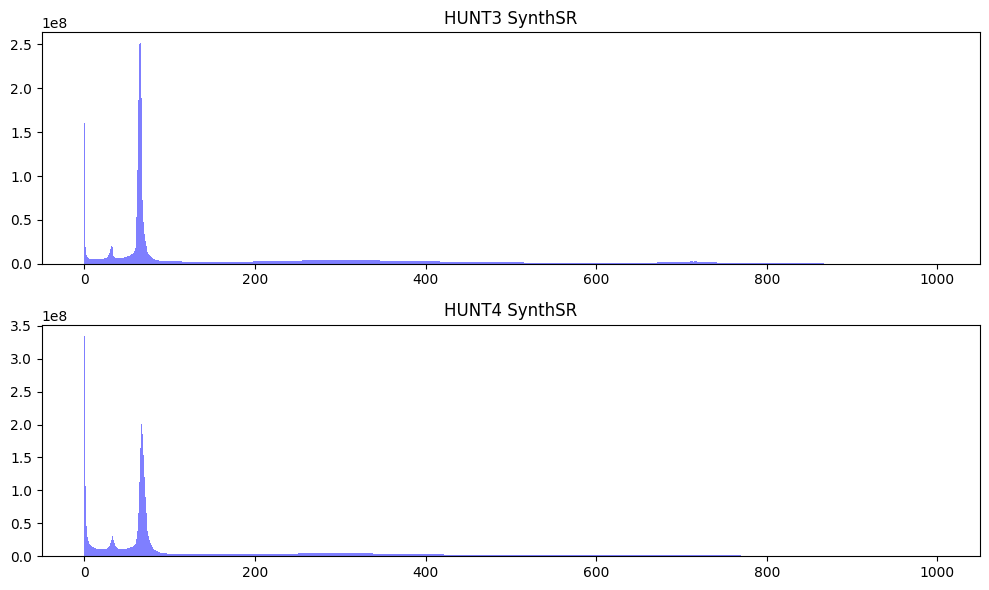

In [4]:

def evaluate_synthsr_histogram():
    num_bins = 1000
    hinst_range = (0, 1)
    hists = np.zeros((2,num_bins), dtype=np.float32)
    metrics_synthsr = [{}, {}]
    nb_images = 0

    for id in tqdm(pil.get_matching_ids()):
        for hunt in pil.HUNTS:
            # img_synthsr, _ = pil.load_nsk_image(hunt, id, absolute=True)
            img_synthsr, _ = pil.load_image(hunt, id, pil.INAME_SYNTHSR_T1.format(id, hunt-3), absolute=True)
            metrics_synthsr[hunt-3] = fc.add_dicts(metrics_synthsr[hunt-3], get_img_metrics(img_synthsr[img_synthsr>0]))

            img_synthsr = util.normalize(img_synthsr, mask=img_synthsr>0, percentile=(0,100))
            hists[hunt-3] += fc.calc_hist(img_synthsr[img_synthsr>0], range=hinst_range, num_bins=num_bins)[0]
        nb_images += 1

    # print metrics
    # nb_images = len(pil.test_patients_ids) * len(pil.HUNTS)
    print("HUNT3 metrics: ", fc.divide_dicts_by_integer(metrics_synthsr[0], nb_images))
    print("HUNT4 metrics: ", fc.divide_dicts_by_integer(metrics_synthsr[1], nb_images))

    # plot histograms
    fig, ax = plt.subplots(2, 1, figsize=(10, 6))
    bins = np.arange(num_bins + 1) 
    fc.plot_precomputed_hist(hists[0], bins, title='HUNT3 SynthSR', ax=ax[0])
    fc.plot_precomputed_hist(hists[1], bins, title='HUNT4 SynthSR', ax=ax[1])

    plt.tight_layout()
    plt.show()

evaluate_synthsr_histogram()

# Evaluate Rigid Registration

## Visualization

### Probability maps

100%|██████████| 395/395 [00:57<00:00,  6.89it/s]


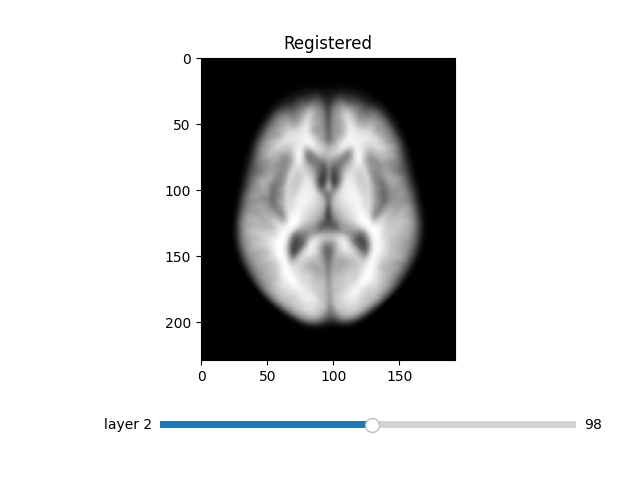

In [5]:
def visualize_probability_map(registration_to=pil.REGISTRATION_TO_MNI):
    %matplotlib widget
    if registration_to == pil.REGISTRATION_TO_HUNT3:
        image_size=(200,240,240)
    else:
        image_size=(193,229,193)

    img_sum = np.zeros((image_size), dtype=np.float32)
    matching_ids = pil.get_matching_ids()
    for id in tqdm(matching_ids):
        # Tu código aquí
        for hunt in pil.HUNTS:
            if registration_to == pil.REGISTRATION_TO_HUNT3 and hunt == pil.HUNTS[0]:
                img, _ = pil.load_preprocessed_image(hunt, id, absolute=True)
            else:
                # img = load_nsk_image(hunt, id, registration_to)
                img, _ = pil.load_preprocessed_image(hunt, id, absolute=True)

            img_sum += img[:image_size[0], :image_size[1], :image_size[2]]
    fc.imgshow_3D(f"Registered", img_sum, current_plane=98)

visualize_probability_map(registration_to=pil.REGISTRATION_TO_MNI)

### Pair images

In [5]:
def visualize_pairwise(registration_to=pil.REGISTRATION_TO_MNI):
    %matplotlib widget
    matching_ids = pil.get_matching_ids()
    for id in tqdm(matching_ids):
        image_size = (200,240,240) if registration_to == pil.REGISTRATION_TO_HUNT3 else (193,229,193)
        img_sum = np.zeros((image_size)+(3,), dtype=np.float32)
        for hunt in pil.HUNTS:
            if registration_to == pil.REGISTRATION_TO_HUNT3 and hunt == pil.HUNTS[0]:
                img = load_nsk_image_hunt3(hunt, id, registration_to)
            else:
                # img = load_nsk_image(hunt, id, registration_to)
                img, _ = pil.load_preprocessed_image(hunt, id, absolute=True)

            img_sum[...,hunt-3] += img[:image_size[0], :image_size[1], :image_size[2]]
        fc.imgshow_3D(f"Registered", img_sum, current_plane=150)
        break
# visualize_pairwise()

## Compute metrics

In [6]:
def compute_pairwise_similarity_metrics(registration_to=pil.REGISTRATION_TO_MNI):
    metrics_list = []
    matching_ids = pil.get_matching_ids()
    for id in tqdm(matching_ids):
        # img_HUNT4 = load_nsk_image(4, id, registration_to)
        img_HUNT4, _ = pil.load_preprocessed_image(4, id, absolute=True)
        if registration_to == pil.REGISTRATION_TO_HUNT3:
            img_HUNT3 = load_nsk_image_hunt3(3, id, registration_to)
        else:
            # img_HUNT3 = load_nsk_image(3, id, registration_to)
            img_HUNT3, _ = pil.load_preprocessed_image(3, id, absolute=True)
        
        metrics = util.get_metrics_dict(img_HUNT3, img_HUNT4)
        metrics_list.append(metrics)

    df = pd.DataFrame(metrics_list)
    return df

df_MNI = compute_pairwise_similarity_metrics()
print(df_MNI.head(100))


# print("-------- TO HUNT3 --------")
# print("-------- elastix")
# df_hunt3_elastix = compute_pairwise_similarity_metrics(parameters_type=pil.PARAMETERS_FILE_SIMILARITY, registration_to=pil.REGISTRATION_TO_HUNT3, library=pil.LIBRARY_ELASTIX)
# print(df_hunt3_elastix)
# print("-------- fresurfer")
# df_hunt3_freesurfer = compute_pairwise_similarity_metrics(parameters_type=pil.PARAMETERS_FILE_AFFINE, registration_to=pil.REGISTRATION_TO_HUNT3, library=pil.LIBRARY_FREESURFER)
# print(df_hunt3_freesurfer)


# print("\n")
# print("-------- TO MNI --------")
# print("-------- elastix")
# df_mni_elastix = compute_pairwise_similarity_metrics(parameters_type=pil.PARAMETERS_FILE_SIMILARITY, registration_to=pil.REGISTRATION_TO_MNI, library=pil.LIBRARY_ELASTIX)
# print(df_mni_elastix)
# print("-------- fresurfer")
# df_mni_freesurfer =compute_pairwise_similarity_metrics(parameters_type=pil.PARAMETERS_FILE_AFFINE, registration_to=pil.REGISTRATION_TO_MNI, library=pil.LIBRARY_FREESURFER)
# print(df_mni_freesurfer)




# -------- TO HUNT3 --------
# -------- elastix
#         rms       ncc        mi      ssim
# 0  0.000010  0.978025  0.714272  0.965415
# 1  0.000009  0.983348  0.729516  0.968365
# 2  0.000010  0.974452  0.678427  0.966256
# 3  0.000010  0.975567  0.673073  0.967375
# 4  0.000011  0.978163  0.759903  0.960714
# 5  0.000010  0.977256  0.744689  0.966186
# 6  0.000012  0.969939  0.624285  0.958579
# 7  0.000013  0.977498  0.741285  0.950219
# 8  0.000009  0.980110  0.664213  0.971763
# -------- fresurfer
#         rms       ncc        mi      ssim
# 0  0.000009  0.983379  0.755181  0.970275
# 1  0.000008  0.986858  0.752910  0.976238
# 2  0.000009  0.978395  0.700187  0.971717
# 3  0.000010  0.975695  0.678612  0.967359
# 4  0.000011  0.979754  0.773049  0.957685
# 5  0.000010  0.978531  0.753223  0.967622
# 6  0.000011  0.978745  0.663705  0.960872
# 7  0.000015  0.980596  0.760335  0.934596
# 8  0.000008  0.984916  0.699263  0.977819


# -------- TO MNI --------
# -------- elastix
#         rms       ncc        mi      ssim
# 0  0.000020  0.948100  0.753832  0.889964
# 1  0.000024  0.920112  0.674229  0.849639
# 2  0.000048  0.658890  0.331527  0.737726
# 3  0.000017  0.965308  0.916328  0.928621
# 4  0.000026  0.918386  0.682057  0.861183
# 5  0.000018  0.963732  0.914136  0.922833
# 6  0.000021  0.950867  0.814986  0.901336
# 7  0.000024  0.934221  0.764376  0.875750
# 8  0.000019  0.961305  0.849316  0.908578
# -------- fresurfer
#         rms       ncc        mi      ssim
# 0  0.000018  0.961040  0.792325  0.915169
# 1  0.000021  0.940483  0.701509  0.878783
# 2  0.000014  0.969289  0.815223  0.949184
# 3  0.000018  0.963284  0.761751  0.924899
# 4  0.000014  0.976625  0.925469  0.951073
# 5  0.000014  0.975214  0.907299  0.951185
# 6  0.000034  0.856177  0.511247  0.797574
# 7  0.000019  0.954794  0.794844  0.915308
# 8  0.000019  0.955097  0.710573  0.916666




# -------- MEAN --------
#                        rms       ncc        mi      ssim
# hunt3_elastix     0.000010  0.977151  0.703296  0.963875
# hunt3_freesurfer  0.000010  0.980763  0.726274  0.964909
# mni_elastix       0.000024  0.913436  0.744532  0.875070
# mni_freesurfer    0.000019  0.950223  0.768915  0.911093


# HUNT3 and HUNT4 to MNI
# 	rms	ncc	mi	ssim
# 0	0.000018	0.96104	0.792325	0.915169

# HUNT3 to MNI then HUNT4 to HUNT3_MNI
# no --affine
# 0	0.000011	0.983563	0.946966	0.965166
# --affine
# 0	0.000014	0.984834	0.875882	0.958254

  0%|          | 0/308 [00:00<?, ?it/s]

100%|██████████| 308/308 [07:42<00:00,  1.50s/it]

         rms       ncc        mi      ssim
0   0.000055  0.937621  0.940372  0.948006
1   0.000065  0.908150  1.032626  0.931933
2   0.000065  0.904220  0.988006  0.936301
3   0.000058  0.937755  0.938981  0.959898
4   0.000079  0.889372  0.922693  0.942541
..       ...       ...       ...       ...
95  0.000049  0.947365  1.066101  0.956191
96  0.000052  0.928175  1.094643  0.946381
97  0.000079  0.865679  0.865909  0.938249
98  0.000064  0.915541  0.890079  0.952455
99  0.000055  0.932719  0.982729  0.959275

[100 rows x 4 columns]


In [7]:
print(df_MNI.mean())


# rms     0.000061
# ncc     0.919432
# mi      0.971110
# ssim    0.950143

rms     0.000061
ncc     0.919432
mi      0.971110
ssim    0.950143
dtype: float64


In [7]:
# Calcula la media de cada DataFrame
mean_hunt3_elastix = df_hunt3_elastix.mean()
mean_hunt3_freesurfer = df_hunt3_freesurfer.mean()
mean_mni_elastix = df_mni_elastix.mean()
mean_mni_freesurfer = df_mni_freesurfer.mean()

# Crea un nuevo DataFrame con las medias
df_means = pd.DataFrame({
    'hunt3_elastix': mean_hunt3_elastix,
    'hunt3_freesurfer': mean_hunt3_freesurfer,
    'mni_elastix': mean_mni_elastix,
    'mni_freesurfer': mean_mni_freesurfer
})

# Transpone el DataFrame para que las métricas sean las columnas y los nombres sean las filas
df_means = df_means.transpose()

print(df_means)

                       rms       ncc        mi      ssim
hunt3_elastix     0.000010  0.977151  0.703296  0.963875
hunt3_freesurfer  0.000010  0.980763  0.726274  0.964909
mni_elastix       0.000024  0.913436  0.744532  0.875070
mni_freesurfer    0.000019  0.950223  0.768915  0.911093


## HUNT3 registration

# MNI

MNI metrics:  {'min': 0.09671436995267868, 'max': 1.0, 'mean': 0.7282759164819713, 'std': 0.14918961423204613}


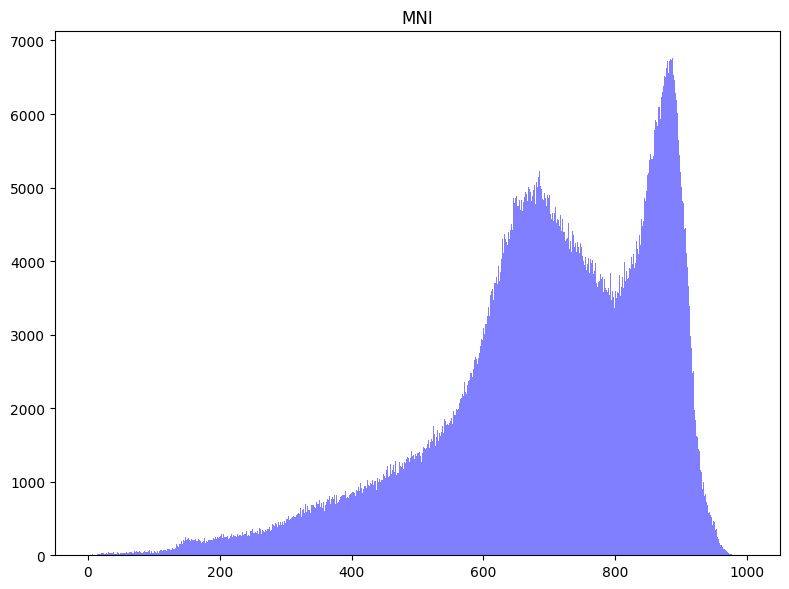

In [ ]:
import numpy as np

def evaluate_MNI_histogram():
    num_bins = 1000
    hinst_range = (0, 1)

    img_MNI, _ = nfc.load_nifti(pil.get_T1_MNI_template_path_name(absolute=True))
    metrics_MNI = get_img_metrics(img_MNI[img_MNI>0])

    img_MNI = util.normalize(img_MNI, mask=img_MNI>0, percentile=(0,100))
    hist = fc.calc_hist(img_MNI[img_MNI>0], range=hinst_range, num_bins=num_bins)[0]

    # print metrics
    # nb_images = len(pil.test_patients_ids) * len(pil.HUNTS)
    print("MNI metrics: ", metrics_MNI)

    # plot histograms
    bins = np.arange(num_bins + 1) 
    fc.plot_precomputed_hist(hist, bins, title='MNI')
    plt.tight_layout()
    plt.show()

evaluate_MNI_histogram()